# Tutorial 5 — Graph-rewrite reactions: a Process that rewires the bigraph

The earlier tutorials built Processes that update **numbers** flowing over
wires. But a bigraph is also a *structure* — a nesting of nodes joined by
links — and a Process can rewrite that **structure itself**: add a node,
delete one, form and break bonds, move a node between compartments, all while
the simulation runs.

`bigraph-schema` supplies this as **Milner-style reaction rules**: a rule is a
pair of bigraphs, a `redex` (what to match) and a `reactum` (what to put in its
place). There is no fixed menu of `add` / `remove` / `rewire` operations —
those are just *effects* of how the reactum differs from the redex.

In this tutorial we:

1. write `add`, `remove`, and `rewire` rules and fire them by hand,
2. run a rule set to quiescence with `run_reactions`,
3. wrap rule-firing in a `process-bigraph` **Process** so it runs on a
   schedule inside a `Composite`,
4. build a small **compartmentalised signalling model** and **watch its
   topology change** — bonds forming and breaking, nodes migrating between
   compartments — drawn with `bigraph-viz`,
5. and point at `viva-reactive-system`, where exactly this pattern drives a
   real MAPK model.

The engine lives in `bigraph_schema.assembly`.

In [1]:
from bigraph_schema.assembly import (
    ReactionRule,   # a redex -> reactum rewrite rule
    fire_rule,      # fire one rule once (first/Nth match)
    find_matches,   # enumerate matches of a redex in a state
    run_reactions,  # fire a rule set until quiescence (or max_steps)
    LinkVar,        # a link-graph variable: shared name == shared edge
    Absent,         # negative precondition: "this key must be absent"
)
from bigraph_schema.schema import Site   # a place-graph hole: matches any subtree
import json

def show(tag, state):
    print(f"--- {tag} ---")
    print(json.dumps(state, default=str, indent=1))

print("imports OK")

imports OK


## 1. The pieces of a rule

A `ReactionRule(redex, reactum, instantiation={}, rate=None, label='')` has:

- **`redex`** — a bigraph *pattern*. Plain keys must find structurally
  matching nodes in the state (subgraph isomorphism).
- **`reactum`** — what replaces the matched region when the rule fires.
- three markers you place *inside* redex/reactum:
  - **`Site()`** — a hole in the *place* graph. It captures "everything else
    here" so the rest of the matched node rides through the rewrite untouched.
  - **`LinkVar(name)`** — a variable in the *link* graph. Two `LinkVar`s with
    the same `name` share one edge; a fresh name in the reactum mints a new
    wire. This is how you **rewire**.
  - **`Absent()`** — a negative application condition: the matched node must
    *not* have this key (or have it empty). This is how you say "unbound".

Our first state is a flat "soup" of named molecule nodes, each a dict with a
`_type` control:

In [2]:
soup = {
    'a1': {'_type': 'A'},
    'a2': {'_type': 'A'},
    'w1': {'_type': 'Waste'},
}
show("initial soup", soup)

--- initial soup ---
{
 "a1": {
  "_type": "A"
 },
 "a2": {
  "_type": "A"
 },
 "w1": {
  "_type": "Waste"
 }
}


## 2. `add` — a rule that creates a node

Reading `A  →  A + C`: wherever there is an `A`, keep it and add a new `C`. The
redex matches one `A` (bound to key `x`) plus a `Site()` that soaks up the rest
of the soup; the reactum keeps `x` and introduces a brand-new node `c`.

In [3]:
add_C = ReactionRule(
    redex   = {'x': {'_type': 'A'}, 'rest': Site()},
    reactum = {'x': {'_type': 'A'}, 'c': {'_type': 'C'}, 'rest': Site()},
    label='add_C',
)

new_soup, match = fire_rule(soup, add_C)
print("fired at path:", match.path if match else None)
show("after add_C", new_soup)   # a 'c' node has appeared

fired at path: ()
--- after add_C ---
{
 "w1": {
  "_type": "Waste"
 },
 "a1": {
  "_type": "A"
 },
 "c": {
  "_type": "C"
 },
 "a2": {
  "_type": "A"
 }
}


## 3. `remove` — a rule that deletes a node

To delete, the reactum simply *omits* the node the redex matched. Here the
redex matches a `Waste` node; the reactum keeps only the `Site()` leftover.

In [4]:
remove_waste = ReactionRule(
    redex   = {'w': {'_type': 'Waste'}, 'rest': Site()},
    reactum = {'rest': Site()},
    label='remove_waste',
)

new_soup, match = fire_rule(soup, remove_waste)
print("fired at path:", match.path if match else None)
show("after remove_waste", new_soup)   # 'w1' is gone

fired at path: ()
--- after remove_waste ---
{
 "a2": {
  "_type": "A"
 },
 "a1": {
  "_type": "A"
 }
}


## 4. `rewire` — form a bond with `LinkVar`, gated by `Absent`

Binding two molecules is a *link-graph* edit:

```
P{free} + Q{free}   →   P—Q      (P and Q share one edge)
```

- A **free** node has no `outputs` wire. The precondition `'outputs': Absent()`
  in the redex makes the rule match only molecules that aren't already bound.
- In the reactum both nodes get an `outputs` port wired to the *same*
  `LinkVar('bond')` — matching names put them on one shared edge.

In [5]:
free_soup = {
    'p1': {'_type': 'P'},   # free: no 'outputs' key
    'q1': {'_type': 'Q'},   # free
    'z1': {'_type': 'Z'},   # a bystander
}

bind = ReactionRule(
    redex   = {'p':    {'_type': 'P', 'outputs': Absent()},
               'q':    {'_type': 'Q', 'outputs': Absent()},
               'rest': Site()},
    reactum = {'p':    {'_type': 'P', 'outputs': {'port': LinkVar('bond')}},
               'q':    {'_type': 'Q', 'outputs': {'port': LinkVar('bond')}},
               'rest': Site()},
    label='bind',
)

bound, match = fire_rule(free_soup, bind)
show("after bind - p1 and q1 share one edge", bound)

# Fire again: no match. Both nodes are now bound, so Absent() fails -- the
# negative precondition keeps the rule from double-binding.
_, again = fire_rule(bound, bind)
print("second fire match:", again.path if again else None, "(None == correctly blocked)")

--- after bind - p1 and q1 share one edge ---
{
 "p1": {
  "_type": "P",
  "outputs": {
   "port": [
    "_edges",
    "~e_1"
   ]
  }
 },
 "q1": {
  "_type": "Q",
  "outputs": {
   "port": [
    "_edges",
    "~e_1"
   ]
  }
 },
 "z1": {
  "_type": "Z"
 }
}
second fire match: None (None == correctly blocked)


## 5. Fire a rule set to quiescence: `run_reactions`

`fire_rule` applies one rule once. `run_reactions(state, rules, max_steps=…)`
keeps firing — in `deterministic` mode, the first matching rule each step —
until nothing matches or `max_steps` is reached. It returns the final state and
the list of `ReactionEvent`s (the firing trace).

In [6]:
dirty = {f'w{i}': {'_type': 'Waste'} for i in range(5)}
dirty['keep'] = {'_type': 'A'}

cleaned, events = run_reactions(dirty, [remove_waste], max_steps=50)
print("firings:", [e.rule_label for e in events])
show("after run_reactions - all Waste cleared", cleaned)

firings: ['remove_waste', 'remove_waste', 'remove_waste', 'remove_waste', 'remove_waste']
--- after run_reactions - all Waste cleared ---
{
 "keep": {
  "_type": "A"
 }
}


## 6. Wrap it in a Process

To run rules *on a schedule* inside a simulation, put the firing in a
`process-bigraph` **Process**. A Process that rewrites structure has two
conventions:

- its port is typed **`tree[node]`** — an opaque bigraph subtree, not a typed
  numeric store, so the engine leaves the `_type` controls alone;
- its output is **`overwrite[tree[node]]`** — each tick *replaces* the subtree
  with the rewritten one (a plain port would try to *merge* / accumulate).

`update()` reads the subtree, fires at most one matching rule, and returns the
new subtree (or `{}` when nothing fired).

In [7]:
import sys, inspect
from process_bigraph import allocate_core
from process_bigraph.composite import Process, Composite
from process_bigraph.emitter import emitter_from_wires

def rebuild_core():
    # register the Process/Step classes defined in this notebook
    return allocate_core(top=dict(inspect.getmembers(sys.modules["__main__"])))


class ReactionProcess(Process):
    # Fire reaction rules over a bigraph subtree, once per tick.
    config_schema = {}

    def initialize(self, config):
        self.rules = config.get('rules', [])

    def inputs(self):
        return {'state': 'tree[node]'}

    def outputs(self):
        return {'state': 'overwrite[tree[node]]'}

    def update(self, state, interval):
        subtree = state.get('state', {})
        for rule in self.rules:
            new_subtree, match = fire_rule(subtree, rule)
            if match is not None:
                return {'state': new_subtree}
        return {}   # quiescent: no rule matched

core = rebuild_core()
print("ReactionProcess registered ->", core.access("ReactionProcess") is not None)

module `viva_emitters.parquet_emitter` not found during dynamic import
skipping `viva_emitters.run_reader` (missing optional dep `polars`)
module `viva_emitters.xarray_emitter` not found during dynamic import


ReactionProcess registered -> True


## 7. A model with real topology

Flat soups are fine for learning the primitives, but the point of bigraphs is
**structure** — nodes nested in compartments, joined by links. Here is a tiny
signalling model with both:

- a **cytoplasm** compartment holds a kinase `K` and three substrates
  (`ERK`), plus a nested empty **nucleus** compartment;
- three rules drive it:
  - **`bind`** — free `K` + free `ERK` form a complex (a shared `LinkVar`
    bond): a *link-graph* edit;
  - **`release`** — the complex breaks; the substrate leaves as `pERK`
    (phosphorylated), `K` is free again;
  - **`import_perk`** — a free `pERK` in the cytoplasm moves *into* the
    nucleus: a *place-graph* edit (the node changes parent).

The whole bigraph lives under one store so the rules' `{'cell': …}` wrapper
matches what the Process is handed.

In [8]:
# a cytoplasm compartment constructor (fixed 'kind' child + whatever we add)
def Cyto(**children):
    return {'_type': 'Compartment', 'kind': {'_type': 'Cytoplasm'}, **children}

def world0():
    return {'cell': Cyto(
        K=  {'_type': 'Kinase'},
        e1= {'_type': 'ERK', 'name': 'e1'},
        e2= {'_type': 'ERK', 'name': 'e2'},
        e3= {'_type': 'ERK', 'name': 'e3'},
        nucleus={'_type': 'Compartment', 'kind': {'_type': 'Nucleus'}},
    )}

bind_rule = ReactionRule(
    redex   = {'cell': Cyto(
        enzyme   ={'_type': 'Kinase', 'outputs': Absent()},
        substrate={'_type': 'ERK', 'name': Site(), 'outputs': Absent()},
        bystanders=Site())},
    reactum = {'cell': Cyto(
        enzyme   ={'_type': 'Kinase', 'outputs': {'port': LinkVar('cplx')}},
        substrate={'_type': 'ERK', 'name': Site(), 'outputs': {'port': LinkVar('cplx')}},
        bystanders=Site())},
    instantiation={'bystanders': 'bystanders', 'name': 'name'},
    label='bind')

release_rule = ReactionRule(
    redex   = {'cell': Cyto(
        enzyme   ={'_type': 'Kinase', 'outputs': {'port': LinkVar('cplx')}},
        substrate={'_type': 'ERK', 'name': Site(), 'outputs': {'port': LinkVar('cplx')}},
        bystanders=Site())},
    reactum = {'cell': Cyto(
        enzyme   ={'_type': 'Kinase'},
        substrate={'_type': 'pERK', 'name': Site()},
        bystanders=Site())},
    instantiation={'bystanders': 'bystanders', 'name': 'name'},
    label='release')

import_rule = ReactionRule(
    redex   = {'cell': Cyto(
        substrate={'_type': 'pERK', 'name': Site(), 'outputs': Absent()},
        inner    ={'_type': 'Compartment', 'kind': {'_type': 'Nucleus'}, 'inner_rest': Site()},
        outer_rest=Site())},
    reactum = {'cell': Cyto(
        inner    ={'_type': 'Compartment', 'kind': {'_type': 'Nucleus'},
                   'inner_rest': Site(), 'substrate': {'_type': 'pERK', 'name': Site()}},
        outer_rest=Site())},
    instantiation={'outer_rest': 'outer_rest', 'inner_rest': 'inner_rest', 'name': 'name'},
    label='import_perk')

rules = [bind_rule, release_rule, import_rule]
print("rules:", [r.label for r in rules])

rules: ['bind', 'release', 'import_perk']


## 8. Run it in a Composite and record a population time series

We drive the model with the same `ReactionProcess`, emitting the whole `world`
subtree each tick. A small `census` counts, per tick, how many substrates are
free `ERK`, bound in a complex, or `pERK` in the nucleus.

In [9]:
def census(world):
    free = complexed = nuclear = 0
    def walk(node, compartment):
        nonlocal free, complexed, nuclear
        if not isinstance(node, dict):
            return
        t = node.get('_type')
        if t in ('ERK', 'pERK'):
            bound = isinstance(node.get('outputs'), dict) and bool(node['outputs'])
            if bound:                               complexed += 1
            elif compartment == 'nucleus' and t == 'pERK': nuclear += 1
            elif t == 'ERK':                        free += 1
            return
        for key, child in node.items():
            if isinstance(child, dict):
                walk(child, key if child.get('_type') == 'Compartment' else compartment)
    walk(world, None)
    return free, complexed, nuclear

core = rebuild_core()
document = {
    'schema': {'world': 'tree[node]'},
    'state': {
        'rx': {
            '_type': 'process', 'address': 'local:ReactionProcess',
            'config': {'rules': rules}, 'interval': 1.0,
            'inputs': {'state': ['world']}, 'outputs': {'state': ['world']},
        },
        'world': world0(),
        'emitter': emitter_from_wires({'time': ['global_time'], 'world': ['world']}),
    },
}

sim = Composite(document, core=core)
sim.run(12)
records = sim.state['emitter']['instance'].query()

times = [r['time'] for r in records]
free, complexed, nuclear = zip(*(census(r['world']) for r in records))
print("time :", list(times))
print("free ERK   :", list(free))
print("complex    :", list(complexed))
print("nucleus pERK:", list(nuclear))

module `viva_emitters.parquet_emitter` not found during dynamic import
skipping `viva_emitters.run_reader` (missing optional dep `polars`)
module `viva_emitters.xarray_emitter` not found during dynamic import


time : [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0]
free ERK   : [3, 2, 2, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]
complex    : [0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0]
nucleus pERK: [0, 0, 0, 0, 0, 0, 0, 1, 2, 3, 3, 3, 3]


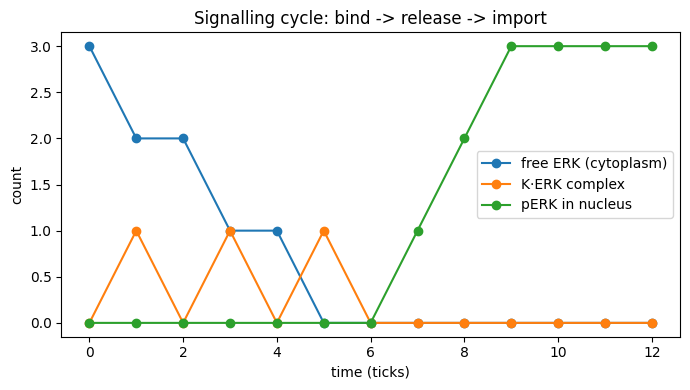

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(times, free,     '-o', label='free ERK (cytoplasm)')
plt.plot(times, complexed,'-o', label='K·ERK complex')
plt.plot(times, nuclear,  '-o', label='pERK in nucleus')
plt.xlabel('time (ticks)'); plt.ylabel('count')
plt.title('Signalling cycle: bind -> release -> import')
plt.legend(); plt.tight_layout(); plt.show()

## 9. Watch the **topology** change

The time series shows *how many* — but the real story is *structural*. Let's
draw the bigraph itself at three moments with
[`bigraph-viz`](https://github.com/vivarium-collective/bigraph-viz)
(`pip install bigraph-viz`, needs Graphviz). Each drawing shows both graphs at
once: the **place graph** (the nesting tree) and the **link graph** (ports and
the dashed hyperedges that join them).

Watch three things change:

- **t0** — a flat cytoplasm: `K`, three free `ERK`s, an empty `nucleus`.
- **middle** — a dashed edge appears: `K` and one `ERK` share a bond
  (`~e…`) — a *link-graph* change.
- **end** — the `pERK` nodes now hang under `nucleus`, not the cytoplasm — a
  *place-graph* change (re-parenting).

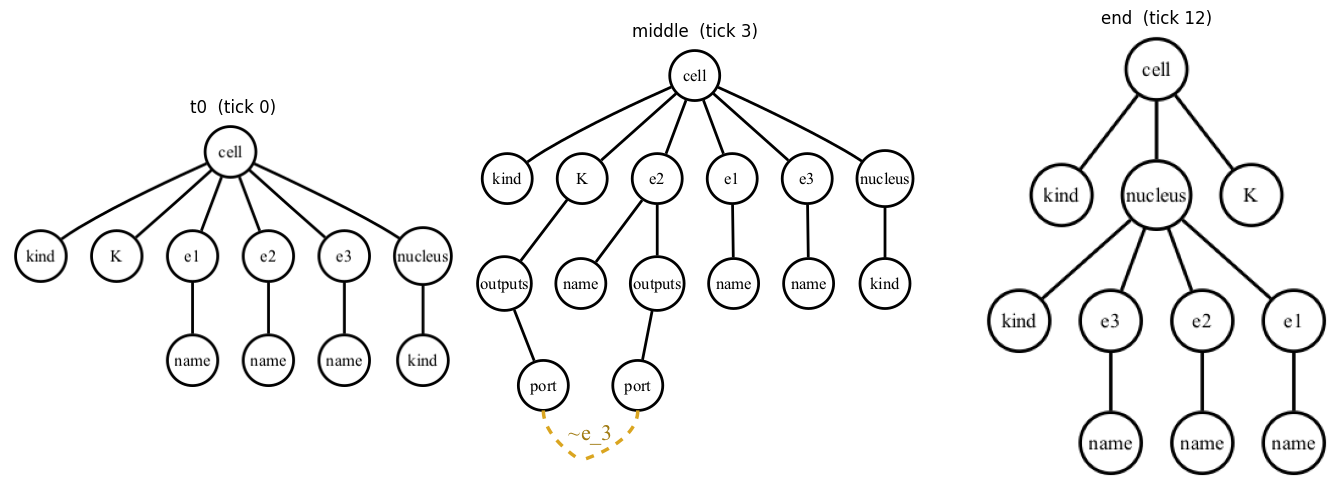

In [11]:
from io import BytesIO
import matplotlib.image as mpimg
from bigraph_viz import plot_bigraph

def snapshot_png(world):
    # plot_bigraph returns a graphviz.Digraph; render it to PNG bytes in-memory.
    digraph = plot_bigraph(world, show_compiled_state=False)
    return digraph.pipe(format='png')

picks = [('t0', 0), ('middle', 3), ('end', len(records) - 1)]
fig, axes = plt.subplots(1, len(picks), figsize=(14, 5))
for ax, (label, i) in zip(axes, picks):
    ax.imshow(mpimg.imread(BytesIO(snapshot_png(records[i]['world']))))
    ax.set_title(f"{label}  (tick {int(records[i]['time'])})")
    ax.axis('off')
plt.tight_layout(); plt.show()

The same three rules — a link edit (`bind`/`release`) and a place edit
(`import_perk`) — turned a flat compartment into a bonded complex and then a
re-nested structure. Scale this up and you get genuinely complex network and
topology dynamics out of a handful of local rewrite rules.

## 10. In the wild: `viva-reactive-system`

The `ReactionProcess` above is a teaching-sized version of
[`viva-reactive-system`](https://github.com/vivarium-collective/viva-reactive-system)'s
`BigraphicalReactiveSystem` — a biology-agnostic Process that fires reaction
rules in three modes: `deterministic`, `stochastic` (propensity ∝
`rule.rate × |matches|`), and a proper Gillespie SSA. It drives a full **MAPK
signalling cycle** over a nested cell bigraph
(`Cell ⊃ Cytoplasm ⊃ {Nucleus, ERLumen}`), discovered, run, and charted by the
vivarium-workbench dashboard.

Its rules use exactly the markers from this tutorial — our `bind`/`release`/
`import_perk` are a stripped-down copy of its `phosphorylate` / `dissociate` /
`translocate_perk_in`. Here is the real `phosphorylate` rule:

```python
# viva-reactive-system/pbg_reactive_system/composites.py
ReactionRule(
    redex={'compartment': {'_type': 'Compartment',
        'enzyme':    {'_type': 'MEK', 'outputs': Absent()},
        'substrate': {'_type': 'ERK', 'name': Site(), 'outputs': Absent()},
        'bystanders': Site()}},
    reactum={'compartment': {'_type': 'Compartment',
        'enzyme':    {'_type': 'MEK', 'outputs': {'enzyme_port':   LinkVar('bond')}},
        'substrate': {'_type': 'pERK', 'name': Site(),
                      'outputs': {'substrate_port': LinkVar('bond')}},
        'bystanders': Site()}},
    instantiation={'bystanders': 'bystanders', 'name': 'name'},
    rate=2.0, label='phosphorylate')
```

## Recap

- A **reaction rule** is `redex → reactum`; `add` / `remove` / `rewire` are
  effects of the diff, not named primitives.
- `Site()` preserves untouched structure, `LinkVar(name)` shares/mints edges
  (**link graph**), `Absent()` is a negative precondition. Re-parenting a node
  in the reactum moves it in the **place graph**.
- `fire_rule` applies one rule once; `run_reactions` fires to quiescence.
- A **Process** with a `tree[node]` input and an `overwrite[tree[node]]` output
  turns rule-firing into a scheduled step you can drop into any `Composite`.
- `bigraph-viz` draws the place + link graph, so you can *see* the topology
  evolve.
- `viva-reactive-system` is the full worked example (MAPK, Gillespie, workbench).